# Experimentos — Detector de puntos calientes (ASICAI)

**Autor:** Christian Masaquiza Jerez · **Proyecto:** Integración de IA en drones termográficos

**Objetivo de este notebook:** entender cómo funciona el detector baseline, ver qué
efecto tiene cada parámetro y dejar documentadas las pruebas (qué se cambió, qué pasó y por qué).

> Nota: las imágenes son **sintéticas** (con ground truth conocido) hasta contar con
> imágenes reales de ASICAI. Los resultados validan el pipeline, no el desempeño en campo.

## 1. Preparación

In [36]:
import sys, os
sys.path.insert(0, os.path.abspath("src"))   # ejecutar el notebook desde la raíz del proyecto

import numpy as np
import cv2
import matplotlib.pyplot as plt

from thermal_simulator import generate_scene
from hotspot_detector import detect_hotspots, draw_detections
from evaluate import match_detections_to_gt, compute_metrics

plt.rcParams["figure.dpi"] = 100
print("Listo")

Listo


## 2. Una escena térmica: qué ve el detector

El detector trabaja sobre una imagen en **escala de grises** (cuanto más brillante, más caliente).
A la derecha se muestra la misma imagen con una paleta de color tipo cámara térmica, solo para verla mejor.

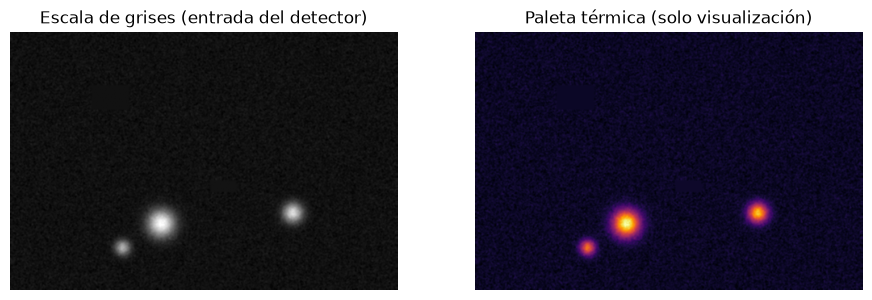

Hotspots reales en esta escena (ground truth):
  centro=(350,224)  severidad=alta  delta_t_proxy=118.7
  centro=(187,237)  severidad=alta  delta_t_proxy=138.4
  centro=(139,267)  severidad=media  delta_t_proxy=92.3


In [37]:
img, gt = generate_scene(n_hotspots=3, seed=7)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(img, cmap="gray");  ax[0].set_title("Escala de grises (entrada del detector)")
ax[1].imshow(img, cmap="inferno"); ax[1].set_title("Paleta térmica (solo visualización)")
for a in ax: a.axis("off")
plt.show()

print("Hotspots reales en esta escena (ground truth):")
for g in gt:
    print(f"  centro=({g['cx']},{g['cy']})  severidad={g['severity']}  delta_t_proxy={g['delta_t_proxy']}")

## 3. El umbral: cómo decide qué es "caliente"

El detector calcula **dos umbrales** y usa el **más alto**:
1. *Percentil* de la imagen (se adapta a cada escena).
2. *Media + k·desviación estándar* (exige que el punto sobresalga del promedio).

El histograma muestra cómo se distribuyen las intensidades y dónde cae el umbral.

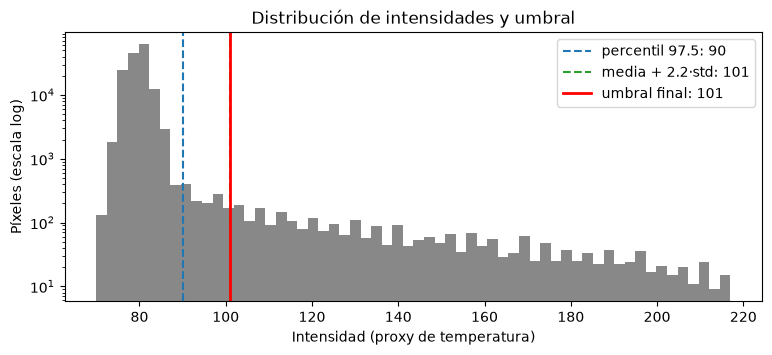

In [38]:
percentile, std_k = 97.5, 2.2
t_percentil = np.percentile(img, percentile)
t_media_std = img.mean() + std_k * img.std()
t_final = max(t_percentil, t_media_std)

plt.figure(figsize=(9, 3.5))
plt.hist(img.ravel(), bins=60, color="#888")
plt.axvline(t_percentil, color="tab:blue",  ls="--", label=f"percentil {percentile}: {t_percentil:.0f}")
plt.axvline(t_media_std, color="tab:green", ls="--", label=f"media + {std_k}·std: {t_media_std:.0f}")
plt.axvline(t_final,     color="red", lw=2, label=f"umbral final: {t_final:.0f}")
plt.yscale("log"); plt.xlabel("Intensidad (proxy de temperatura)"); plt.ylabel("Píxeles (escala log)")
plt.legend(); plt.title("Distribución de intensidades y umbral"); plt.show()

## 4. Detección sobre la escena

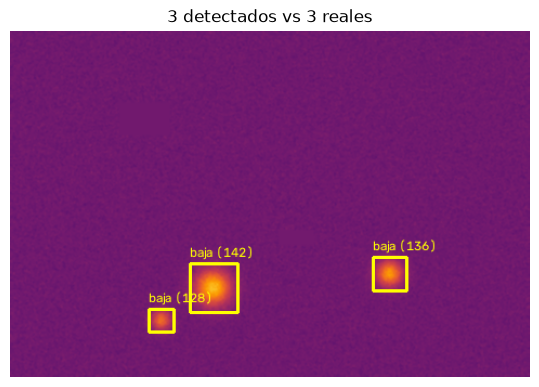

Métricas de esta escena: {'verdaderos_positivos': 3, 'falsos_negativos': 0, 'falsos_positivos': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0}


In [39]:
detecciones = detect_hotspots(img, percentile=97.5, min_area_px=20, std_k=2.2)
anotada = draw_detections(cv2.applyColorMap(img, cv2.COLORMAP_INFERNO), detecciones)

plt.figure(figsize=(7, 4.5))
plt.imshow(cv2.cvtColor(anotada, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"{len(detecciones)} detectados vs {len(gt)} reales"); plt.show()

matches, fn, fp = match_detections_to_gt(detecciones, gt)
print("Métricas de esta escena:", compute_metrics(matches, fn, fp))

## 5. Evaluación sobre un conjunto de escenas

Función auxiliar: corre el detector con ciertos parámetros sobre 30 escenas sintéticas
y devuelve las métricas globales. La usamos en los experimentos de abajo.

In [47]:
ESCENAS = [generate_scene(n_hotspots=int(1 + i % 3), seed=2000 + i) for i in range(30)]

def evaluar(percentile=97.5, min_area_px=20, std_k=2.2):
    todos_m, todos_fn, todos_fp = [], [], []
    for im, gt_ in ESCENAS:
        det = detect_hotspots(im, percentile=percentile, min_area_px=min_area_px, std_k=std_k)
        m, f_n, f_p = match_detections_to_gt(det, gt_)
        todos_m += m; todos_fn += f_n; todos_fp += f_p
    return compute_metrics(todos_m, todos_fn, todos_fp)

base = evaluar()
print("Configuración base:", base)

Configuración base: {'verdaderos_positivos': 57, 'falsos_negativos': 3, 'falsos_positivos': 0, 'precision': 1.0, 'recall': 0.95, 'f1_score': 0.974}


## 6. Experimento A — ¿Qué pasa si bajo el umbral?

Bajamos `std_k` (qué tanto debe sobresalir un punto del promedio). Con valores bajos el
umbral se acerca al ruido de fondo → esperamos **más falsos positivos** (baja la precisión).

 std_k  precision   recall    FP    FN
   0.0      0.397    0.867    79     8
   0.5      0.525    0.883    48     7
   1.0        1.0    0.933     0     4
   1.5        1.0    0.933     0     4
   2.2        1.0     0.95     0     3
   3.0        1.0     0.95     0     3
   4.0        1.0     0.95     0     3


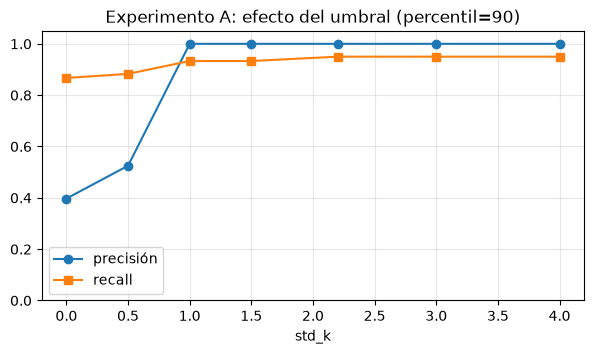

In [41]:
valores_k = [0.0, 0.5, 1.0, 1.5, 2.2, 3.0, 4.0]
res_k = [evaluar(percentile=90, std_k=k) for k in valores_k]

print(f"{'std_k':>6} {'precision':>10} {'recall':>8} {'FP':>5} {'FN':>5}")
for k, r in zip(valores_k, res_k):
    print(f"{k:>6} {r['precision']:>10} {r['recall']:>8} {r['falsos_positivos']:>5} {r['falsos_negativos']:>5}")

plt.figure(figsize=(7, 3.5))
plt.plot(valores_k, [r["precision"] for r in res_k], "o-", label="precisión")
plt.plot(valores_k, [r["recall"] for r in res_k], "s-", label="recall")
plt.xlabel("std_k"); plt.ylim(0, 1.05); plt.legend(); plt.grid(alpha=.3)
plt.title("Experimento A: efecto del umbral (percentil=90)"); plt.show()

**Mi interpretación (completar con tus palabras):**
- ¿Con qué valor de `std_k` empieza a caer la precisión?
- ¿Y el recall, cuándo cae? ¿Por qué un umbral muy alto hace perder puntos?
- ¿Cuál valor elegirías para mantenimiento predictivo, y por qué?

## 7. Experimento B — ¿Qué pasa si subo el área mínima?

`min_area_px` descarta detecciones muy pequeñas (ruido). Pero si es demasiado alto,
descarta también hotspots reales pequeños → esperamos **más falsos negativos**.

 area_min  precision   recall    FP    FN
        5        0.7    0.933    24     4
       20        1.0    0.933     0     4
       60        1.0    0.933     0     4
      150        1.0    0.933     0     4
      300        1.0    0.933     0     4
      600        1.0    0.917     0     5


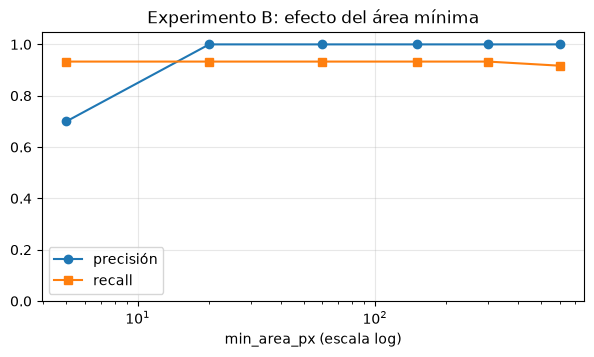

In [42]:
valores_area = [5, 20, 60, 150, 300, 600]
res_a = [evaluar(min_area_px=a) for a in valores_area]

print(f"{'area_min':>9} {'precision':>10} {'recall':>8} {'FP':>5} {'FN':>5}")
for a, r in zip(valores_area, res_a):
    print(f"{a:>9} {r['precision']:>10} {r['recall']:>8} {r['falsos_positivos']:>5} {r['falsos_negativos']:>5}")

plt.figure(figsize=(7, 3.5))
plt.plot(valores_area, [r["precision"] for r in res_a], "o-", label="precisión")
plt.plot(valores_area, [r["recall"] for r in res_a], "s-", label="recall")
plt.xscale("log"); plt.xlabel("min_area_px (escala log)"); plt.ylim(0, 1.05)
plt.legend(); plt.grid(alpha=.3); plt.title("Experimento B: efecto del área mínima"); plt.show()

**Mi interpretación (completar con tus palabras):**
- ¿A partir de qué área se empiezan a perder hotspots reales?
- ¿Qué implicaría esto con imágenes reales de dron, donde la altura de vuelo cambia el tamaño de un punto caliente en píxeles?

## 8. Ver el error con tus propios ojos

Con un umbral demasiado bajo, mira qué marca el detector de más. Esto es lo que
los números de arriba no te muestran.

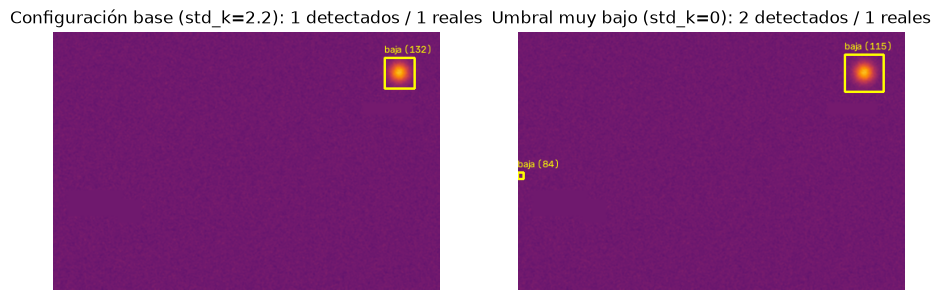

In [43]:
im, gt_ = ESCENAS[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (k, titulo) in zip(ax, [(2.2, "Configuración base (std_k=2.2)"), (0.0, "Umbral muy bajo (std_k=0)")]):
    det = detect_hotspots(im, percentile=90, std_k=k)
    vis = draw_detections(cv2.applyColorMap(im, cv2.COLORMAP_INFERNO), det)
    a.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); a.axis("off")
    a.set_title(f"{titulo}: {len(det)} detectados / {len(gt_)} reales")
plt.show()

## 9. Conclusiones y limitaciones

(Completar al terminar tus pruebas)

- **Qué aprendí de los parámetros:** …
- **Configuración que recomendaría y por qué:** …
- **Limitaciones:** datos sintéticos; el detector clásico no distingue un hotspot real de un reflejo solar o de un objeto caliente por diseño (motor, chimenea). Eso es lo que justificaría pasar a un modelo YOLO entrenado con imágenes reales.
- **Siguiente paso:** repetir estos experimentos con imágenes reales de ASICAI.